In [2]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
csv_path = "diabetes.csv"

if not os.path.exists("/content/diabetes.csv"):
    try:
        from google.colab import files
        print("Please upload the diabetes.csv file from your computer.")
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
        if not csv_candidates:
            raise FileNotFoundError("No CSV file was uploaded. Please upload diabetes.csv.")
        csv_path = csv_candidates[0]
    except ImportError:
        csv_candidates = glob.glob("*.csv")
        if not csv_candidates:
            raise FileNotFoundError(
                "Place diabetes.csv in the same folder as this notebook, then rerun this cell."
            )
        csv_path = csv_candidates[0]

df = pd.read_csv(csv_path)
print(f"Loaded file: {csv_path}")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Loaded file: diabetes.csv
Dataset shape: 768 rows × 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe().T)

print("\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nTarget distribution:")
display(df["Outcome"].value_counts(dropna=False).sort_index().to_frame("Count"))

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values per column:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Target distribution:


,Count
Outcome,
0,500
1,268


In [6]:
required_columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        "The CSV is missing expected columns: "
        + ", ".join(missing_columns)
        + ". Please use the Pima Indians diabetes.csv dataset."
    )

df = df[required_columns].copy()

# Convert columns to numeric in case the CSV contains values stored as text.
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep only rows with a known binary target.
df = df[df["Outcome"].isin([0, 1])].copy()
df["Outcome"] = df["Outcome"].astype(int)

invalid_zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zero values before replacement:")
display((df[invalid_zero_columns] == 0).sum().to_frame("Zero count"))

df[invalid_zero_columns] = df[invalid_zero_columns].replace(0, np.nan)

print("Missing values after replacing invalid zeros:")
display(df.isna().sum().to_frame("Missing count"))
print(f"Rows available after basic target validation: {len(df)}")

Zero values before replacement:


,Zero count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Missing values after replacing invalid zeros:


,Missing count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Rows available after basic target validation: 768


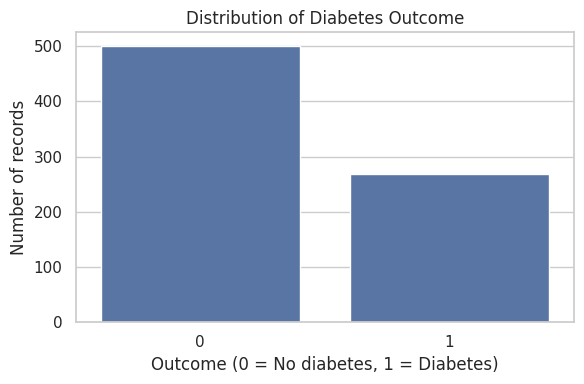

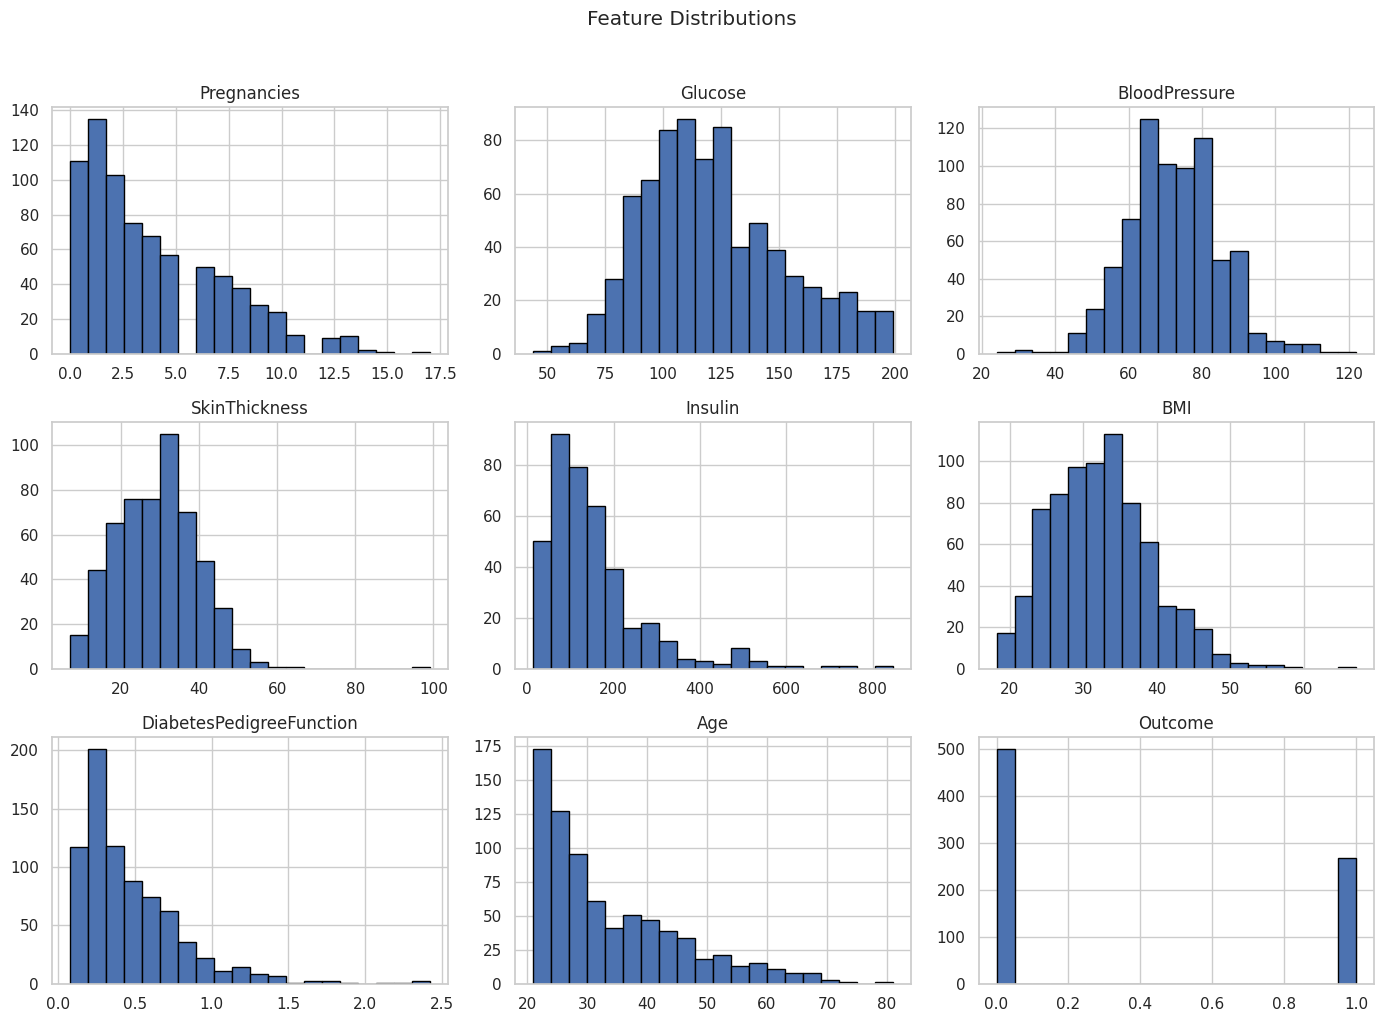

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("Proportion").to_frame())
print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("Proportion").to_frame())

Training feature shape: (614, 8)
Testing feature shape: (154, 8)

Training target proportions:


,Proportion
Outcome,
0,0.651466
1,0.348534



Testing target proportions:


,Proportion
Outcome,
0,0.649351
1,0.350649


In [9]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [10]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
metrics_df = pd.DataFrame(
    {"Metric": list(metrics.keys()), "Result": list(metrics.values())}
)
display(metrics_df.style.format({"Result": "{:.3f}"}))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

,Metric,Result
0,Accuracy,0.734
1,Precision,0.603
2,Recall,0.704
3,F1-score,0.650
4,ROC-AUC,0.813



Classification report:
                 precision    recall  f1-score   support

No diabetes (0)       0.82      0.75      0.79       100
   Diabetes (1)       0.60      0.70      0.65        54

       accuracy                           0.73       154
      macro avg       0.71      0.73      0.72       154
   weighted avg       0.75      0.73      0.74       154



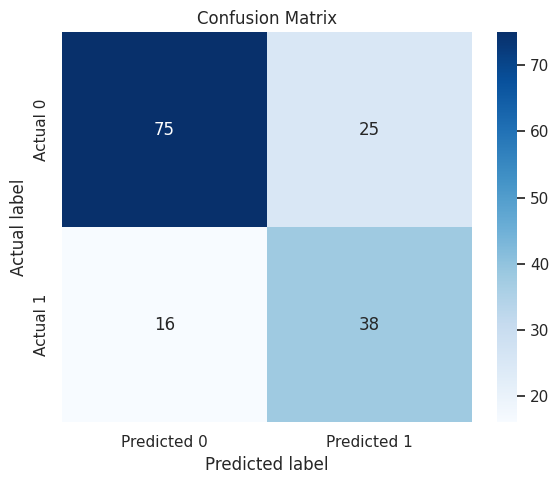

True negatives (TN): 75
False positives (FP): 25
False negatives (FN): 16
True positives (TP): 38


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP): {tp}")

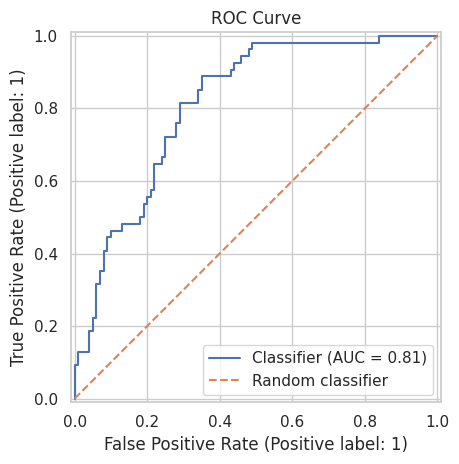

In [12]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Coefficient,Absolute coefficient
1,Glucose,1.1835,1.1835
5,BMI,0.7096,0.7096
0,Pregnancies,0.3729,0.3729
6,DiabetesPedigreeFunction,0.2877,0.2877
7,Age,0.1864,0.1864
3,SkinThickness,0.0140,0.0140
2,BloodPressure,-0.0146,0.0146
4,Insulin,-0.0446,0.0446


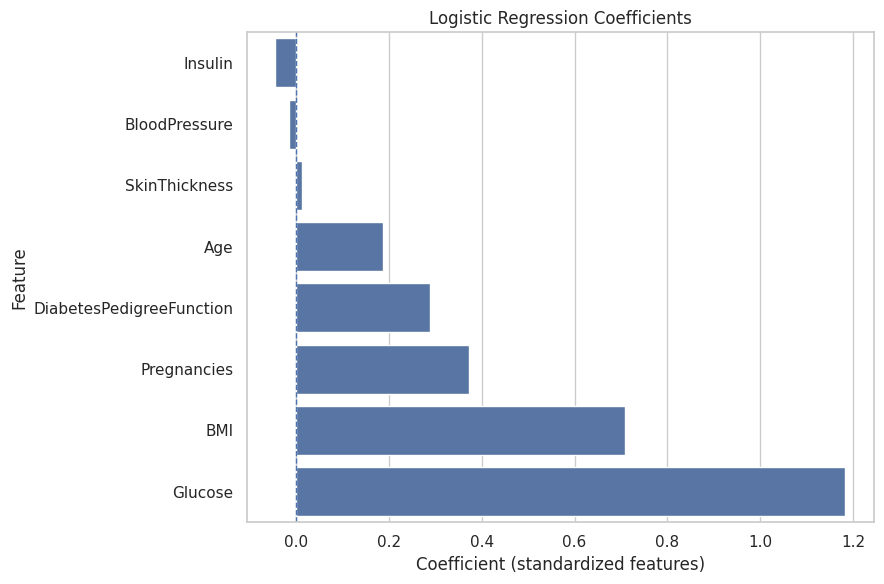

In [13]:
classifier = model.named_steps["classifier"]
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": classifier.coef_[0]
})
coef_df["Absolute coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Coefficient", ascending=False)

display(coef_df.style.format({
    "Coefficient": "{:.4f}",
    "Absolute coefficient": "{:.4f}"
}))

plt.figure(figsize=(9, 6))
plot_df = coef_df.sort_values("Coefficient")
sns.barplot(data=plot_df, x="Coefficient", y="Feature")
plt.axvline(0, linestyle="--", linewidth=1)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (standardized features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [14]:
sample_person = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 30
}])

In [15]:
sample_prediction = int(model.predict(sample_person)[0])
sample_probability = float(model.predict_proba(sample_person)[0, 1])

print("Predicted class:", sample_prediction,
      "(1 = model predicts diabetes class; 0 = model predicts non-diabetes class)")
print(f"Model-estimated probability for class 1: {sample_probability:.1%}")
print("Educational demonstration only — not a medical diagnosis.")

Predicted class: 0 (1 = model predicts diabetes class; 0 = model predicts non-diabetes class)
Model-estimated probability for class 1: 28.0%
Educational demonstration only — not a medical diagnosis.
